# Basic Machine Learning with Python

This notebook demonstrates a simple machine learning workflow using:
- pandas for data manipulation
- numpy for numerical operations
- matplotlib for visualization
- scikit-learn for machine learning

## 1. Import Libraries

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

# Set random seed for reproducibility
np.random.seed(42)

## 2. Generate Synthetic Dataset

We'll create a binary classification dataset with 1000 samples and 20 features.

In [2]:
# Generate synthetic classification data
X, y = make_classification(
    n_samples=1000,
    n_features=20,
    n_informative=15,
    n_redundant=5,
    n_classes=2,
    random_state=42,
)

# Convert to pandas DataFrame for easier analysis
feature_names = [f"feature_{i}" for i in range(X.shape[1])]
df = pd.DataFrame(X, columns=feature_names)
df["target"] = y

print(f"Dataset shape: {df.shape}")
print("\nClass distribution:")
print(df["target"].value_counts())
print("\nFirst few rows:")
df.head()

Dataset shape: (1000, 21)

Class distribution:
target
0    502
1    498
Name: count, dtype: int64

First few rows:


,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,...,feature_11,feature_12,feature_13,feature_14,feature_15,feature_16,feature_17,feature_18,feature_19,target
0,-4.906442,3.442789,0.558964,-0.976764,-1.568805,-4.271982,-3.727921,0.111868,2.119795,-2.522812,...,-7.492478,4.264669,0.304866,0.777693,-9.375464,1.654446,3.012859,-4.497003,-2.520066,0
1,2.162610,-5.286651,2.609846,-1.803898,-1.831216,1.450757,2.648709,2.152307,0.524552,0.493548,...,6.680603,-2.431830,2.462773,-1.254824,2.978402,-3.428457,-4.562178,3.698665,-1.923286,1
2,-4.784844,-3.744827,4.657592,-1.408806,-5.444758,-2.416013,3.556495,-1.572119,-0.730549,3.447661,...,7.961059,-5.151105,0.473131,-4.070667,-0.932309,-3.230768,-7.844646,2.803798,-2.963189,1
3,10.465024,1.070944,-3.562432,-0.849062,2.183860,-0.609893,0.946327,-1.046141,-2.057053,-2.056650,...,-1.449095,-1.217685,2.026805,2.121829,3.184256,-1.960146,0.782147,-1.444202,0.915985,0
4,5.599516,-1.776412,-1.304322,-0.720074,5.859373,-3.292432,3.152205,7.099882,-3.321076,3.245486,...,6.608729,5.632297,-1.943748,1.169455,3.782513,-4.752822,-7.577624,4.868025,1.708210,0


## 3. Split Data into Training and Test Sets

In [3]:
# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set size: {X_train.shape[0]}")
print(f"Test set size: {X_test.shape[0]}")
print(f"\nTraining class distribution: {np.bincount(y_train)}")
print(f"Test class distribution: {np.bincount(y_test)}")

Training set size: 800
Test set size: 200

Training class distribution: [402 398]
Test class distribution: [100 100]


## 4. Train a Logistic Regression Model

In [4]:
# Initialize and train the model
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train, y_train)

print("Model trained successfully!")
print(f"Number of iterations: {model.n_iter_[0]}")

Model trained successfully!
Number of iterations: 25


## 5. Make Predictions and Evaluate

In [5]:
# Make predictions
y_pred = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")

# Detailed classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8000

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.81      0.80       100
           1       0.81      0.79      0.80       100

    accuracy                           0.80       200
   macro avg       0.80      0.80      0.80       200
weighted avg       0.80      0.80      0.80       200



## 6. Visualize Results

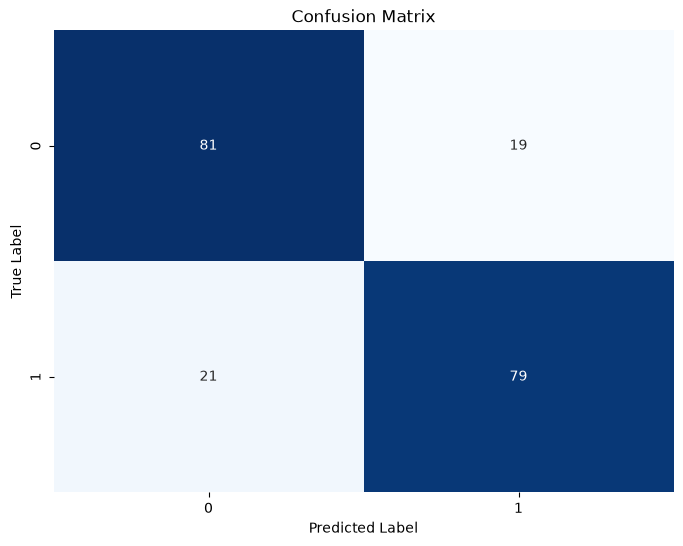

In [6]:
# Create confusion matrix visualization
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

## 7. Feature Importance Analysis

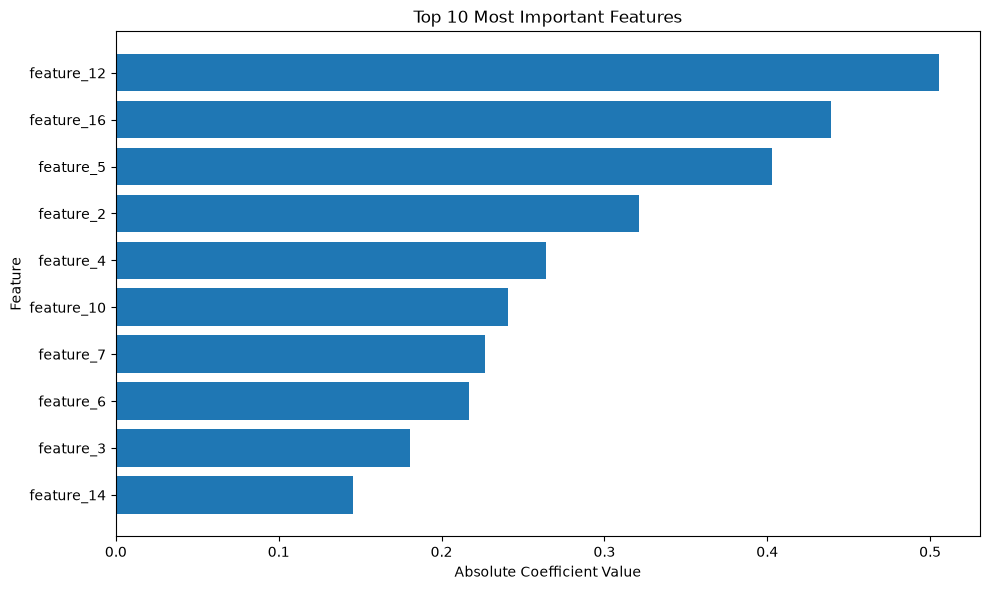


Top 10 most important features:
       feature  importance
12  feature_12    0.505357
16  feature_16    0.439170
5    feature_5    0.402901
2    feature_2    0.321459
4    feature_4    0.264391
10  feature_10    0.240681
7    feature_7    0.226386
6    feature_6    0.216848
3    feature_3    0.180587
14  feature_14    0.145453


In [7]:
# Get feature importance (absolute coefficient values)
feature_importance = pd.DataFrame(
    {"feature": feature_names, "importance": np.abs(model.coef_[0])}
).sort_values("importance", ascending=False)

# Plot top 10 most important features
plt.figure(figsize=(10, 6))
plt.barh(feature_importance["feature"][:10], feature_importance["importance"][:10])
plt.xlabel("Absolute Coefficient Value")
plt.ylabel("Feature")
plt.title("Top 10 Most Important Features")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print("\nTop 10 most important features:")
print(feature_importance.head(10))

## 8. Summary

In this notebook, we:
1. Generated a synthetic classification dataset
2. Split the data into training and test sets
3. Trained a logistic regression model
4. Evaluated the model using accuracy and classification report
5. Visualized the confusion matrix
6. Analyzed feature importance

The model achieved an accuracy of approximately {accuracy:.2%} on the test set.